<a href="https://colab.research.google.com/github/gokulfuture/Sentiment-analysis-NLP/blob/main/Copy_of_Sentiment_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1.Dataset Preparation

Import Required libraries

In [ ]:

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns


import re


from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression


from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving Tweets.csv to Tweets.csv


In [ ]:
df = pd.read_csv(list(uploaded.keys())[0])

print("Dataset loaded successfully!")

Dataset loaded successfully!


Explore Dataset

In [ ]:
print("Dataset Shape:", df.shape)

Dataset Shape: (14640, 2)


In [ ]:
print(df.columns)

Index(['tweet_id', 'airline_sentiment', 'airline_sentiment_confidence',
       'negativereason', 'negativereason_confidence', 'airline',
       'airline_sentiment_gold', 'name', 'negativereason_gold',
       'retweet_count', 'text', 'tweet_coord', 'tweet_created',
       'tweet_location', 'user_timezone'],
      dtype='object')


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14640 entries, 0 to 14639
Data columns (total 15 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   tweet_id                      14640 non-null  int64  
 1   airline_sentiment             14640 non-null  object 
 2   airline_sentiment_confidence  14640 non-null  float64
 3   negativereason                9178 non-null   object 
 4   negativereason_confidence     10522 non-null  float64
 5   airline                       14640 non-null  object 
 6   airline_sentiment_gold        40 non-null     object 
 7   name                          14640 non-null  object 
 8   negativereason_gold           32 non-null     object 
 9   retweet_count                 14640 non-null  int64  
 10  text                          14640 non-null  object 
 11  tweet_coord                   1019 non-null   object 
 12  tweet_created                 14640 non-null  object 
 13  t

In [ ]:
print(df['airline_sentiment'].value_counts())

airline_sentiment
negative    9178
neutral     3099
positive    2363
Name: count, dtype: int64


Select required column

In [ ]:
df = df[['text', 'airline_sentiment']]

df.columns = ['text', 'sentiment']

df.head()

,text,sentiment
0,@VirginAmerica What @dhepburn said.,neutral
1,@VirginAmerica plus you've added commercials t...,positive
2,@VirginAmerica I didn't today... Must mean I n...,neutral
3,@VirginAmerica it's really aggressive to blast...,negative
4,@VirginAmerica and it's a really big bad thing...,negative


# 2.Data cleaning and visualization

Handle missing values and duplicates

In [ ]:

print(df.isnull().sum())

text         0
sentiment    0
dtype: int64


In [ ]:
df = df.dropna()

df = df.drop_duplicates()

print("Dataset after cleaning:", df.shape)

Dataset after cleaning: (14452, 2)


Visualize sentiment distribution

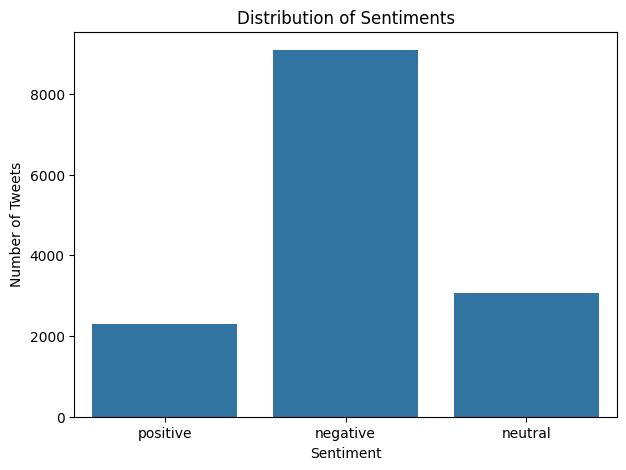

In [ ]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='sentiment',
    order=['positive', 'negative', 'neutral']
)

plt.title("Distribution of Sentiments")
plt.xlabel("Sentiment")
plt.ylabel("Number of Tweets")

plt.show()

# 3: Text preprocessing

Clean the text

In [ ]:
def clean_text(text):

    text = text.lower()

    text = re.sub(r'http\S+|www\S+', '', text)

    text = re.sub(r'@\w+', '', text)

    text = text.replace('#', '')

    text = re.sub(r'[^a-z\s]', '', text)

    text = re.sub(r'\s+', ' ', text).strip()

    return text

In [ ]:
df['cleaned_text'] = df['text'].apply(clean_text)

df[['text', 'cleaned_text']].head(10)

,text,cleaned_text
0,@VirginAmerica What @dhepburn said.,what said
1,@VirginAmerica plus you've added commercials t...,plus youve added commercials to the experience...
2,@VirginAmerica I didn't today... Must mean I n...,i didnt today must mean i need to take another...
3,@VirginAmerica it's really aggressive to blast...,its really aggressive to blast obnoxious enter...
4,@VirginAmerica and it's a really big bad thing...,and its a really big bad thing about it
5,@VirginAmerica seriously would pay $30 a fligh...,seriously would pay a flight for seats that di...
6,"@VirginAmerica yes, nearly every time I fly VX...",yes nearly every time i fly vx this ear worm w...
7,@VirginAmerica Really missed a prime opportuni...,really missed a prime opportunity for men with...
8,"@virginamerica Well, I didn't…but NOW I DO! :-D",well i didntbut now i do d
9,"@VirginAmerica it was amazing, and arrived an ...",it was amazing and arrived an hour early youre...


# 4.Machine learning implementation

Separate input and output

In [ ]:
X = df['cleaned_text']

y = df['sentiment']

print("Input data:")
print(X.head())

print("\nOutput labels:")
print(y.head())

Input data:
0                                            what said
1    plus youve added commercials to the experience...
2    i didnt today must mean i need to take another...
3    its really aggressive to blast obnoxious enter...
4              and its a really big bad thing about it
Name: cleaned_text, dtype: object

Output labels:
0     neutral
1    positive
2     neutral
3    negative
4    negative
Name: sentiment, dtype: object


Split the dataset

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", len(X_train))
print("Testing data:", len(X_test))

Training data: 11561
Testing data: 2891


Convert text into numerical values using TF-IDF

In [ ]:
tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2)
)

X_train_tfidf = tfidf.fit_transform(X_train)

X_test_tfidf = tfidf.transform(X_test)

print("Training features:", X_train_tfidf.shape)

print("Testing features:", X_test_tfidf.shape)

Training features: (11561, 5000)
Testing features: (2891, 5000)


Train the Logistic Regression model

In [ ]:
model = LogisticRegression(max_iter=1000)

model.fit(X_train_tfidf, y_train)

print("Model trained successfully!")

Model trained successfully!


# 5: Model evaluation

Predict the testing data

In [ ]:
y_pred = model.predict(X_test_tfidf)

print("Prediction completed!")

Prediction completed!


In [ ]:
results = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred
})

results.head(15)

,Actual,Predicted
0,neutral,neutral
1,negative,negative
2,negative,negative
3,neutral,positive
4,negative,negative
5,negative,negative
6,neutral,neutral
7,negative,negative
8,negative,negative
9,negative,negative


Calculate model accuracy

In [ ]:
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

Model Accuracy: 79.10757523348322 %


Classification report

In [ ]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

    negative       0.81      0.94      0.87      1818
     neutral       0.68      0.49      0.57       613
    positive       0.82      0.59      0.69       460

    accuracy                           0.79      2891
   macro avg       0.77      0.68      0.71      2891
weighted avg       0.78      0.79      0.78      2891



Confusion matrix

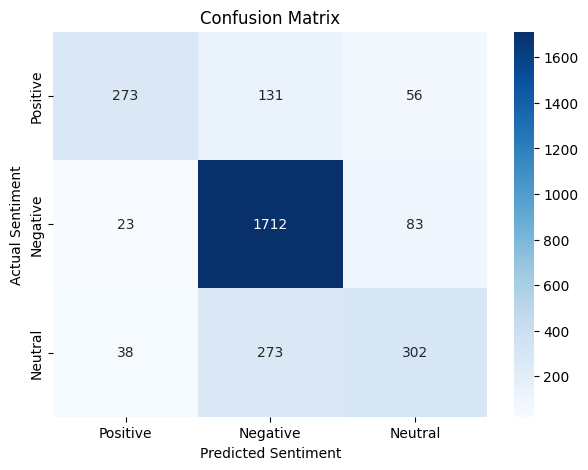

In [ ]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=['positive', 'negative', 'neutral']
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Positive', 'Negative', 'Neutral'],
    yticklabels=['Positive', 'Negative', 'Neutral']
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")

plt.show()

6.Test sentences

Create a sentiment prediction function

In [ ]:
def predict_sentiment(sentence):


    cleaned = clean_text(sentence)


    vectorized = tfidf.transform([cleaned])


    prediction = model.predict(vectorized)

    print("Input Sentence:", sentence)

    print("Predicted Sentiment:", prediction[0])

In [ ]:
predict_sentiment("I love this airline and its service")

Input Sentence: I love this airline and its service
Predicted Sentiment: positive


In [ ]:
predict_sentiment("This is the worst flight experience")

Input Sentence: This is the worst flight experience
Predicted Sentiment: negative


In [ ]:
predict_sentiment("What time does the flight depart?")

Input Sentence: What time does the flight depart?
Predicted Sentiment: neutral


The project demonstrates the application of Natural Language Processing in sentiment analysis. A Twitter airline sentiment dataset was used to classify text into positive, negative and neutral categories. Text preprocessing was performed to clean the tweets, and TF-IDF was used to convert text into numerical features. A Logistic Regression classifier was trained and evaluated using accuracy, precision, recall, F1-score and a confusion matrix. The trained model was also tested with new user-provided sentences